### 3. Análisis exploratorio de datos (EDA)

### 3.1. Librerías y configuración

In [1]:
from pathlib import Path
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Python:", sys.version.split()[0])
print("Sistema:", platform.system())
print("Ejecutable:", sys.executable)
print("Pandas:", pd.__version__)
print("Scikit-learn se utilizará en la siguiente etapa.")

Python: 3.13.5
Sistema: Windows
Ejecutable: c:\Users\Asus\Desktop\Maestria\MachineLearning\online-retail-clustering\.venv\Scripts\python.exe
Pandas: 3.0.6
Scikit-learn se utilizará en la siguiente etapa.


### 3.2. Carga y verificación del dataset

In [2]:
# Compatible con notebooks ubicados en la raíz del proyecto o en notebooks/.
posibles_rutas = [
    Path("data/raw/Online Retail.xlsx"),
    Path("../data/raw/Online Retail.xlsx"),
]
ruta_dataset = next((ruta for ruta in posibles_rutas if ruta.is_file()), None)
if ruta_dataset is None:
    raise FileNotFoundError(
        "Coloca 'Online Retail.xlsx' dentro de data/raw/ y ejecuta el notebook "
        "desde la raíz del proyecto o desde la carpeta notebooks/."
    )

df = pd.read_excel(ruta_dataset, engine="openpyxl")
columnas_esperadas = {
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
}
faltantes_en_archivo = columnas_esperadas - set(df.columns)
if faltantes_en_archivo:
    raise ValueError(f"Faltan columnas esperadas: {faltantes_en_archivo}")

# Conversión de tipos para las operaciones exploratorias (sin descartar filas).
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
for columna in ["Quantity", "UnitPrice"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

print(f"Archivo: {ruta_dataset.resolve()}")
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
display(df.head(10))

Archivo: C:\Users\Asus\Desktop\Maestria\MachineLearning\online-retail-clustering\data\raw\Online Retail.xlsx
Filas: 541,909 | Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,"17,850.00",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,"17,850.00",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,"13,047.00",United Kingdom


### 3.3. Estructura, tipos de datos y cardinalidad

In [3]:
print("--- Información general ---")
df.info(show_counts=True)

print("\n--- Resumen de columnas ---")
resumen_columnas = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(dropna=True),
})
resumen_columnas["porcentaje_nulos"] = (resumen_columnas["nulos"] / len(df) * 100).round(2)
display(resumen_columnas)

print("\nRango de fechas:", df["InvoiceDate"].min(), "a", df["InvoiceDate"].max())

--- Información general ---
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

--- Resumen de columnas ---


,tipo,no_nulos,nulos,unicos,porcentaje_nulos
InvoiceNo,object,541909,0,25900,0.00
StockCode,object,541909,0,4070,0.00
Description,object,540455,1454,4223,0.27
Quantity,int64,541909,0,722,0.00
InvoiceDate,datetime64[us],541909,0,23260,0.00
UnitPrice,float64,541909,0,1630,0.00
CustomerID,float64,406829,135080,4372,24.93
Country,str,541909,0,38,0.00



Rango de fechas: 2010-12-01 08:26:00 a 2011-12-09 12:50:00


### 3.4. Calidad de los registros

La exploración de calidad permitirá fundamentar las reglas de preparación posteriores. Una factura marcada como cancelada puede no ser equivalente a una compra efectiva; asimismo, no se podrá construir el perfil de un cliente si falta su identificador.

,Cantidad
Filas totales,541909
Filas duplicadas exactas,5268
CustomerID faltante,135080
Description faltante,1454
InvoiceDate faltante/no convertible,0
Facturas marcadas C (líneas),9288
Quantity negativa,10624
Quantity igual a 0,0
UnitPrice negativo,2
UnitPrice igual a 0,2515


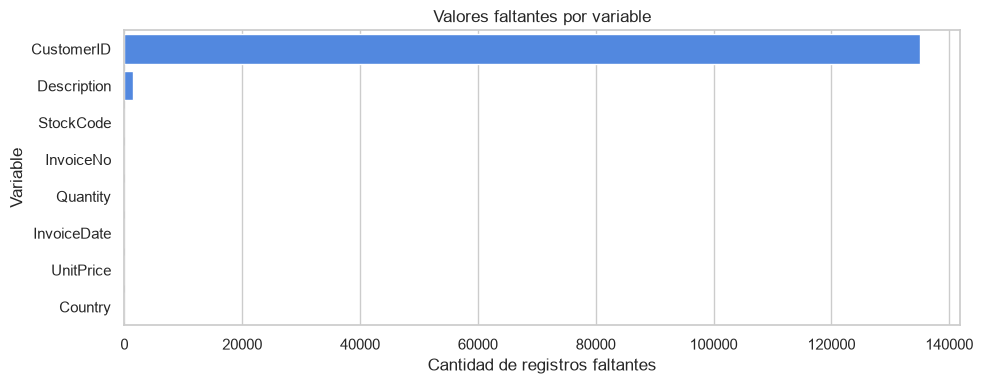

In [4]:
# El prefijo C identifica cancelaciones de acuerdo con la documentación original.
es_cancelacion = (
    df["InvoiceNo"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)

indicadores_calidad = pd.Series({
    "Filas totales": len(df),
    "Filas duplicadas exactas": int(df.duplicated().sum()),
    "CustomerID faltante": int(df["CustomerID"].isna().sum()),
    "Description faltante": int(df["Description"].isna().sum()),
    "InvoiceDate faltante/no convertible": int(df["InvoiceDate"].isna().sum()),
    "Facturas marcadas C (líneas)": int(es_cancelacion.sum()),
    "Quantity negativa": int((df["Quantity"] < 0).sum()),
    "Quantity igual a 0": int((df["Quantity"] == 0).sum()),
    "UnitPrice negativo": int((df["UnitPrice"] < 0).sum()),
    "UnitPrice igual a 0": int((df["UnitPrice"] == 0).sum()),
})
display(indicadores_calidad.to_frame("Cantidad"))

faltantes = df.isna().sum().sort_values(ascending=False)
if faltantes.sum() > 0:
    plt.figure(figsize=(10, 4))
    sns.barplot(x=faltantes.values, y=faltantes.index, color="#3B82F6")
    plt.title("Valores faltantes por variable")
    plt.xlabel("Cantidad de registros faltantes")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.show()
else:
    print("No se han detectado valores nulos en las columnas originales.")

### 3.5. Estadística descriptiva de variables numéricas

In [5]:
columnas_numericas = ["Quantity", "UnitPrice"]
resumen_numerico = df[columnas_numericas].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
display(resumen_numerico)

print("\nConteos importantes (sin agregación):")
print("Clientes identificados:", f"{df['CustomerID'].nunique(dropna=True):,}")
print("Facturas distintas:", f"{df['InvoiceNo'].nunique(dropna=True):,}")
print("Productos distintos:", f"{df['StockCode'].nunique(dropna=True):,}")
print("Países distintos:", f"{df['Country'].nunique(dropna=True):,}")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",-2.00,1.00,1.00,3.00,10.00,29.00,100.00,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",0.19,0.42,1.25,2.08,4.13,9.95,18.00,"38,970.00"



Conteos importantes (sin agregación):
Clientes identificados: 4,372
Facturas distintas: 25,900
Productos distintos: 4,070
Países distintos: 38


### 3.6. Vista provisional de compras positivas

Para analizar volumen y evolución de compras se crea una vista provisional con cantidades y precios positivos, fechas disponibles y facturas no marcadas como canceladas. Esta selección no modifica df y no constituye todavía la limpieza definitiva. No se excluyen por ahora los registros sin CustomerID de la estadística general de ventas, pero sí del análisis a nivel de cliente.
El importe por línea se define como: Quantity × UnitPrice (libras esterlinas). Es una aproximación a ventas brutas de las líneas seleccionadas, no beneficio ni ventas netas de devoluciones.

In [6]:
mascara_compra = (
    df["Quantity"].gt(0)
    & df["UnitPrice"].gt(0)
    & df["InvoiceDate"].notna()
    & ~es_cancelacion
)

ventas_validas = df.loc[mascara_compra].copy()
ventas_validas["ImporteLinea"] = (
    ventas_validas["Quantity"] * ventas_validas["UnitPrice"]
)
ventas_validas["Mes"] = ventas_validas["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

ventas_clientes = ventas_validas.loc[ventas_validas["CustomerID"].notna()].copy()

print("Filas originales:", f"{len(df):,}")
print("Líneas positivas y no canceladas:", f"{len(ventas_validas):,}")
print("Líneas con cliente identificable:", f"{len(ventas_clientes):,}")
print("Clientes en la vista:", f"{ventas_clientes['CustomerID'].nunique():,}")
print("Importe bruto provisional (£):", f"{ventas_validas['ImporteLinea'].sum():,.2f}")
display(ventas_validas.head(5))

Filas originales: 541,909
Líneas positivas y no canceladas: 530,104
Líneas con cliente identificable: 397,884
Clientes en la vista: 4,338
Importe bruto provisional (£): 10,666,684.54


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ImporteLinea,Mes
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,2010-12-01


### 3.7. Evolución mensual de las ventas

Se visualizan la suma de importes positivos y el número de facturas únicas de la vista provisional. Los meses inicial y final pueden ser incompletos debido a la cobertura del dataset; no deben compararse sin considerar esa limitación temporal.

,Mes,ImporteBruto,Facturas
0,2010-12-01,"823,746.14",1559
1,2011-01-01,"691,364.56",1086
2,2011-02-01,"523,631.89",1100
3,2011-03-01,"717,639.36",1454
4,2011-04-01,"537,808.62",1246
5,2011-05-01,"770,536.02",1681
6,2011-06-01,"761,739.90",1533
7,2011-07-01,"719,221.19",1475
8,2011-08-01,"759,138.38",1361
9,2011-09-01,"1,058,590.17",1837


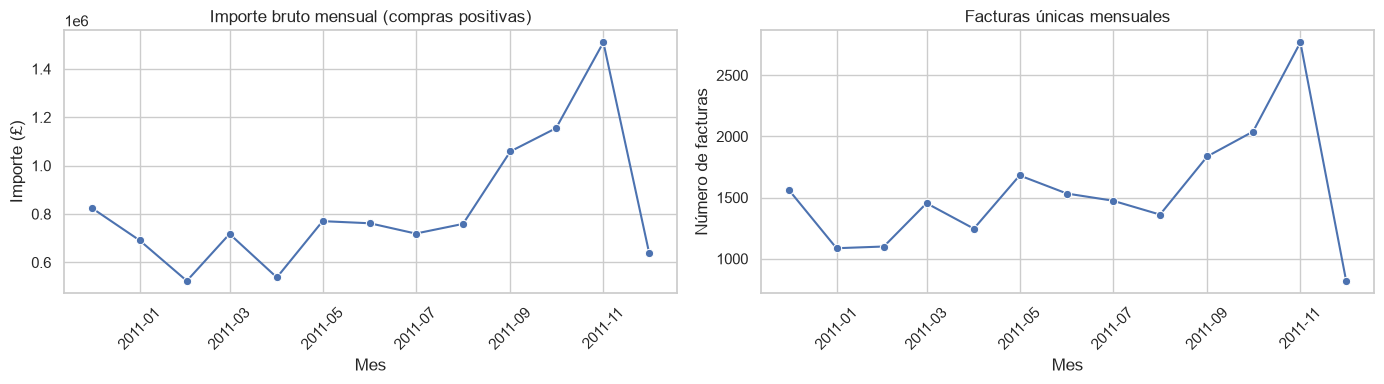

In [7]:
mensual = (
    ventas_validas.groupby("Mes", as_index=False)
    .agg(ImporteBruto=("ImporteLinea", "sum"), Facturas=("InvoiceNo", "nunique"))
    .sort_values("Mes")
)
display(mensual)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=mensual, x="Mes", y="ImporteBruto", marker="o", ax=axes[0])
axes[0].set(title="Importe bruto mensual (compras positivas)", xlabel="Mes", ylabel="Importe (£)")
axes[0].tick_params(axis="x", rotation=45)
sns.lineplot(data=mensual, x="Mes", y="Facturas", marker="o", ax=axes[1])
axes[1].set(title="Facturas únicas mensuales", xlabel="Mes", ylabel="Número de facturas")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 3.8. Distribución geográfica de clientes identificados

,Clientes,Facturas
Country,,
United Kingdom,3920,16646
Germany,94,457
France,87,389
Spain,30,90
Belgium,25,98
Switzerland,21,51
Portugal,19,57
Italy,14,38
Finland,12,41


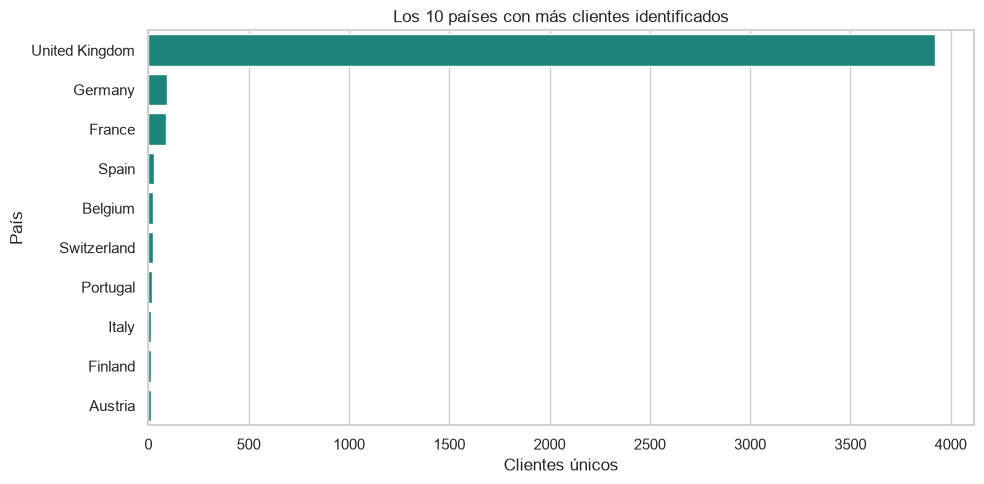

In [8]:
paises = (
    ventas_clientes.groupby("Country", dropna=False)
    .agg(Clientes=("CustomerID", "nunique"), Facturas=("InvoiceNo", "nunique"))
    .sort_values("Clientes", ascending=False)
)
display(paises.head(10))

plt.figure(figsize=(10, 5))
sns.barplot(x=paises.head(10)["Clientes"], y=paises.head(10).index, color="#0D9488")
plt.title("Los 10 países con más clientes identificados")
plt.xlabel("Clientes únicos")
plt.ylabel("País")
plt.tight_layout()
plt.show()

### 3.9. Distribuciones y posibles valores atípicos

Las distribuciones de compra pueden presentar asimetría: muchos pedidos pequeños y unas pocas operaciones de gran magnitud. Se aplica log1p (solo para visualizar) a cantidades, precios e importes positivos. Esto no sustituye la transformación que se decida implementar en el pipeline posterior.

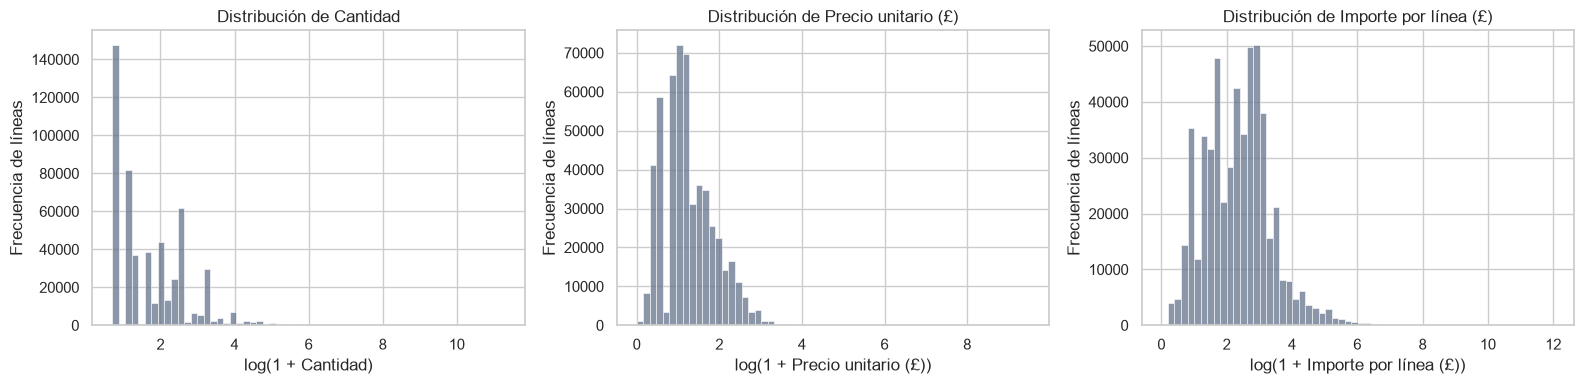

Percentiles de los importes por línea (compras positivas):


,Importe (£)
0.50,9.90
0.75,17.70
0.95,59.70
0.99,183.60
1.00,835.20


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
variables = [
    ("Quantity", "Cantidad"),
    ("UnitPrice", "Precio unitario (£)"),
    ("ImporteLinea", "Importe por línea (£)"),
]
for ax, (col, nombre) in zip(axes, variables):
    valores = np.log1p(ventas_validas[col].dropna())
    sns.histplot(valores, bins=60, ax=ax, color="#64748B")
    ax.set_title(f"Distribución de {nombre}")
    ax.set_xlabel(f"log(1 + {nombre})")
    ax.set_ylabel("Frecuencia de líneas")
plt.tight_layout()
plt.show()

print("Percentiles de los importes por línea (compras positivas):")
display(ventas_validas["ImporteLinea"].quantile([0.50, 0.75, 0.95, 0.99, 0.999]).to_frame("Importe (£)"))

### 3.10. Exploración inicial por cliente (sin clustering)

El objetivo final es segmentar clientes, no facturas individuales. Por ello, evaluamos algunas medidas agregadas preliminares. En la siguiente etapa construiremos formalmente RFM y definiremos transformaciones y tratamiento de extremos. La tabla creada aquí es únicamente exploratoria.

Clientes evaluables: 4,338


,FacturasUnicas,ImporteTotal,ProductosDistintos,PrimeraCompra,UltimaCompra
CustomerID,,,,,
"12,346.00",1,"77,183.60",1,2011-01-18 10:01:00,2011-01-18 10:01:00
"12,347.00",7,"4,310.00",103,2010-12-07 14:57:00,2011-12-07 15:52:00
"12,348.00",4,"1,797.24",22,2010-12-16 19:09:00,2011-09-25 13:13:00
"12,349.00",1,"1,757.55",73,2011-11-21 09:51:00,2011-11-21 09:51:00
"12,350.00",1,334.40,17,2011-02-02 16:01:00,2011-02-02 16:01:00


,count,mean,std,min,25%,50%,75%,95%,99%,max
FacturasUnicas,"4,338.00",4.27,7.70,1.00,1.00,2.00,5.00,13.00,30.00,209.00
ImporteTotal,"4,338.00","2,054.27","8,989.23",3.75,307.41,674.49,"1,661.74","5,841.84","19,881.00","280,206.02"
ProductosDistintos,"4,338.00",61.50,85.37,1.00,16.00,35.00,77.00,205.00,354.00,"1,787.00"


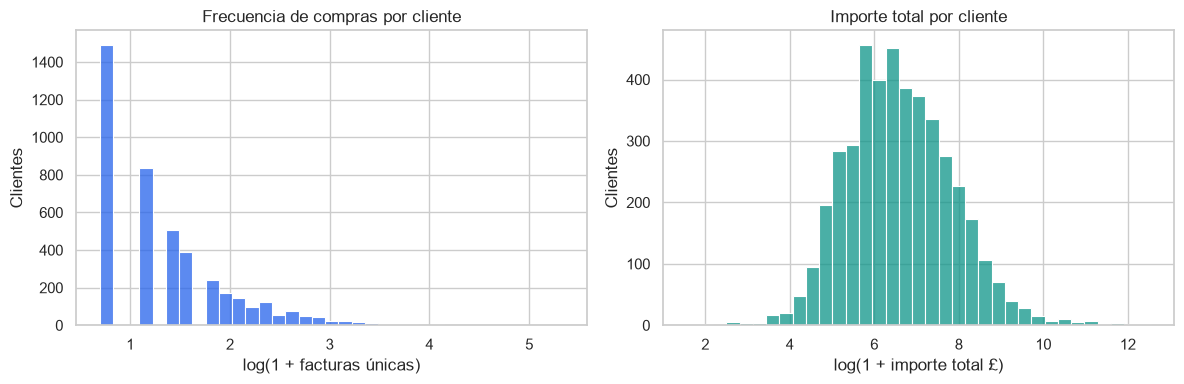

In [10]:
exploracion_clientes = (
    ventas_clientes.groupby("CustomerID")
    .agg(
        FacturasUnicas=("InvoiceNo", "nunique"),
        ImporteTotal=("ImporteLinea", "sum"),
        ProductosDistintos=("StockCode", "nunique"),
        PrimeraCompra=("InvoiceDate", "min"),
        UltimaCompra=("InvoiceDate", "max"),
    )
)
print("Clientes evaluables:", f"{len(exploracion_clientes):,}")
display(exploracion_clientes.head())
display(exploracion_clientes[["FacturasUnicas", "ImporteTotal", "ProductosDistintos"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(exploracion_clientes["FacturasUnicas"]), bins=35, ax=axes[0], color="#2563EB")
axes[0].set(title="Frecuencia de compras por cliente", xlabel="log(1 + facturas únicas)", ylabel="Clientes")
sns.histplot(np.log1p(exploracion_clientes["ImporteTotal"]), bins=35, ax=axes[1], color="#0D9488")
axes[1].set(title="Importe total por cliente", xlabel="log(1 + importe total £)", ylabel="Clientes")
plt.tight_layout()
plt.show()

### 3.11. Resumen reproducible de hallazgos

In [12]:
porcentaje = lambda cantidad, total: 100 * cantidad / total if total else 0.0

print("=== INDICADORES DE CONCLUSIONES DEL EDA ===")
print(f"Tamaño: {len(df):,} filas y {df.shape[1]} columnas")
print(f"Periodo observado: {df['InvoiceDate'].min()} — {df['InvoiceDate'].max()}")
print(f"CustomerID ausente: {df['CustomerID'].isna().sum():,} "
      f"({porcentaje(df['CustomerID'].isna().sum(), len(df)):.2f}%)")
print(f"Duplicados exactos: {df.duplicated().sum():,} "
      f"({porcentaje(df.duplicated().sum(), len(df)):.2f}%)")
print(f"Líneas de facturas marcadas C: {es_cancelacion.sum():,} "
      f"({porcentaje(es_cancelacion.sum(), len(df)):.2f}%)")
print(f"Líneas de compras positivas: {len(ventas_validas):,} "
      f"({porcentaje(len(ventas_validas), len(df)):.2f}%)")
print(f"Clientes identificables en las compras positivas: {len(exploracion_clientes):,}")
print(f"Mediana de facturas por cliente: {exploracion_clientes['FacturasUnicas'].median():.1f}")
print(f"Mediana de importe por cliente: £{exploracion_clientes['ImporteTotal'].median():,.2f}")
if len(paises):
    print(f"País con más clientes identificados: {paises.index[0]}")

=== INDICADORES DE CONCLUSIONES DEL EDA ===
Tamaño: 541,909 filas y 8 columnas
Periodo observado: 2010-12-01 08:26:00 — 2011-12-09 12:50:00
CustomerID ausente: 135,080 (24.93%)
Duplicados exactos: 5,268 (0.97%)
Líneas de facturas marcadas C: 9,288 (1.71%)
Líneas de compras positivas: 530,104 (97.82%)
Clientes identificables en las compras positivas: 4,338
Mediana de facturas por cliente: 2.0
Mediana de importe por cliente: £674.49
País con más clientes identificados: United Kingdom


### 4. Conclusiones del análisis exploratorio de datos

El análisis exploratorio del dataset *Online Retail* permitió identificar características relevantes para el desarrollo del modelo de segmentación. Se evidenció que el 24,93 % de los registros carece de identificador de cliente, mientras que el 0,97 % corresponde a duplicados exactos. Asimismo, se encontraron cancelaciones, precios no positivos y valores extremos que requieren un tratamiento adecuado durante el preprocesamiento.

Las variables numéricas presentan distribuciones asimétricas, con predominio de transacciones de bajo importe y algunas operaciones de magnitud considerable. Esto justifica evaluar técnicas de transformación y escalamiento para reducir la influencia de valores extremos en los algoritmos de clustering.

Finalmente, se identificaron 4.338 clientes con compras positivas y una mediana de gasto acumulado de £674,49, lo que proporciona una base para construir características de comportamiento de compra. Estos hallazgos orientan la siguiente etapa del proyecto, enfocada en la limpieza de los datos y la generación de variables RFM para identificar patrones de consumo mediante aprendizaje no supervisado.